In [1]:
# Standard libraries for use throughout the entire notebook
import numpy as np
import numpy.random as random
import pandas as pd
from pandas import Series, DataFrame
import warnings

# Display up to three decimal places
%precision 3

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

# Ignore warnings
warnings.filterwarnings('ignore')

# scikit-learn building blocks used in multiple sections
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import r2_score, accuracy_score


In [2]:
# Regression task: California Housing
from sklearn.datasets import fetch_california_housing

california_housing = fetch_california_housing(as_frame=True)
X_housing = california_housing.data
y_housing = california_housing.target

# Classification task: Breast Cancer
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
X_cancer = cancer.data
y_cancer = cancer.target

print('California Housing:', X_housing.shape, '/ target:', y_housing.shape)
print('Breast Cancer    :', X_cancer.shape,  '/ target:', y_cancer.shape)


California Housing: (20640, 8) / target: (20640,)
Breast Cancer    : (569, 30) / target: (569,)


** FEATURE ENGINEERING** This is the process of selecting, transforming or creating variables to make your data  more meaningful to the model.

UNDER_FITTING -  this occurs when a model is too simple that the model lacks crucial signals from it to learn from.

OVERFITTING -  happens when a model clings too tightly to training data fitting noise rather than true patterns.Can be achieved by dimensionality reduction (reducing the number of features)

Types of feature engineering

1. Using general purpose methods that are not dependent on the problem setting
2. Relying on domain specific knowledge related to the problem setting.

General purpose feature engineering is further divided into two :

1. Transforming features - this refers to transforming the data for the model to handle inputs easier
2. Creating features to improve model's performance.

In transforming numerical varibles , applied methods include:
1. standardization which is rescaling a feature so that its mean is zero and its standard deviation is 1.
2. normalizing which is rescaling so the minimum is 0 and the mazimum is 1.





In [3]:
# Import from scikit-learn
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

# Load data
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['target'] = iris.target

# Extract target variables
x = df[['sepal length (cm)']]

# Create and apply StandardScaler
ss = StandardScaler()
x_std = ss.fit_transform(x)

# Compare pre- and post-transformation values
x['sepal length std'] = x_std
display(x)

# Compare pre- and post-transformation (mean and standard deviation)
x.describe().loc[['mean', 'std'], :]

,sepal length (cm),sepal length std
0,5.1,-0.900681
1,4.9,-1.143017
2,4.7,-1.385353
3,4.6,-1.506521
4,5.0,-1.021849
...,...,...
145,6.7,1.038005
146,6.3,0.553333
147,6.5,0.795669
148,6.2,0.432165


,sepal length (cm),sepal length std
mean,5.843333,-4.736952e-16
std,0.828066,1.003350e+00


Conducting an experiment on the iris data set to see how scaling and normalizing.
Later comparing between logistic regression and model tree.

In [4]:
# Import from scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# Preparing data
X = df[['sepal length (cm)']]
y = df.loc[:, "target"]

# Split into training and test datasets
X_train, X_valid, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Prepare models
mods = {
    'LogisticRegression': LogisticRegression(C=0.01, random_state=42),
    'StandardScaler + LogisticRegression': Pipeline([('ss', StandardScaler()), ('model', LogisticRegression(C=0.01, random_state=42))]),
    'DecisonTree': DecisionTreeClassifier(random_state=42),
    'StandardScaler + DecisonTree': Pipeline([('ss', StandardScaler()), ('model', DecisionTreeClassifier(random_state=42))])
}

# Model training and evaluation
results = {}
for mod_name, mod in mods.items():
    mod.fit(X_train, y_train)
    results[(mod_name, 'train')] = round(accuracy_score(y_train, mod.predict(X_train)), 3)
    results[(mod_name, 'valid')] = round(accuracy_score(y_test, mod.predict(X_valid)), 3)

# Organizing the results
pd.Series(results).unstack().iloc[[1, 3, 0, 2]]

,train,valid
LogisticRegression,0.610,0.533
StandardScaler + LogisticRegression,0.705,0.600
DecisonTree,0.771,0.756
StandardScaler + DecisonTree,0.771,0.756


Logarithimic transformation is used to correct skewed distribution and applying the log function.
Applying the log function compresses the large values and stretches the small ones.

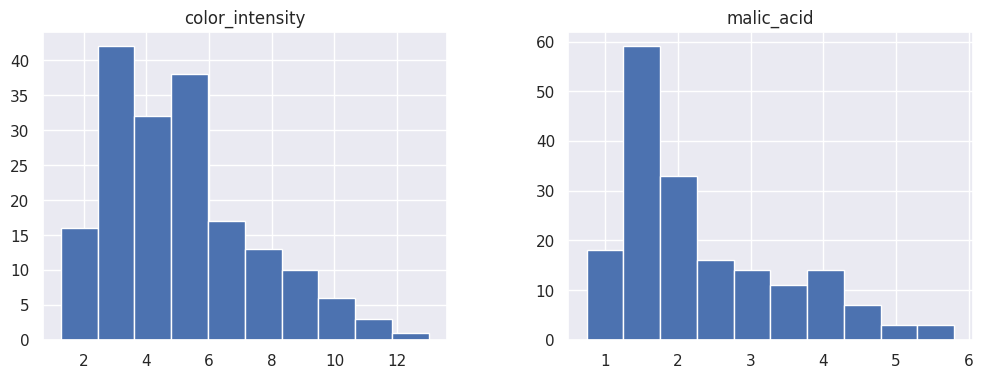

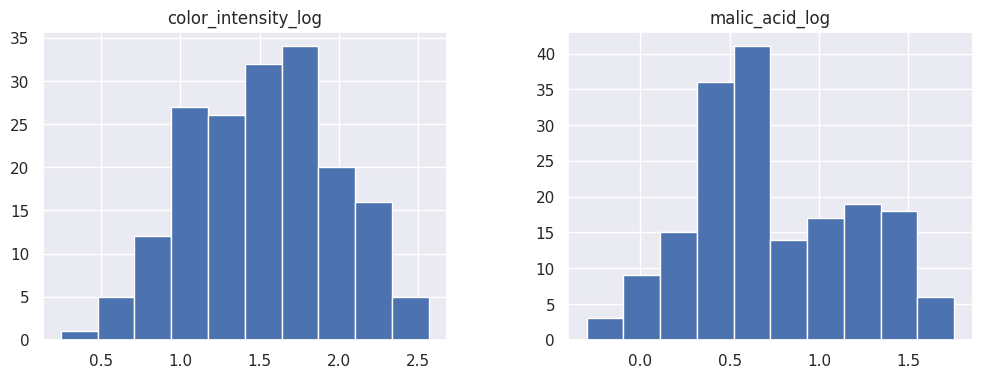

In [5]:
# Import from scikit-learn
from sklearn.datasets import load_wine

# Load data
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
df['variety'] = wine.target

# Extract target variables
cols = ['color_intensity', 'malic_acid']
X = df[cols]

# Display original distributions
X.hist(figsize=(12, 4))

# Apply logarithmic transformation
X_log = np.log(X)
cols_log = [s + '_log' for s in cols]
X_log.columns = cols_log

# Display transformed distributions
X_log.hist(figsize=(12, 4))
plt.show()

 TRANSFORMING CATEGORICAL VARIABLES
 1. Label Encoding - assigns each distinct category a unique interger.

 2. One hot encoding - creates a separate 0/1 coloumn for each category and sets the coloumn matching the row's category to 1.



In [6]:
# Titanic data (Kaggle-style schema) — loaded directly from a public mirror,
# so the notebook works without Google Drive / Kaggle credentials.
TITANIC_URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(TITANIC_URL)

# Extract the Embarked column for the one-hot encoding demo below.
x = df['Embarked']

# Fill missing values with the most frequent value, 'S'.
x = x.fillna('S')

# Inspect the column
x.head(10)


,Embarked
0,S
1,C
2,S
3,S
4,S
5,Q
6,S
7,S
8,S
9,C


Cross features are useful when the target depends on the interaction that a simple model cannot easily on its own.

In [7]:
# Select numeric Titanic columns for the demo (Age has NaNs — impute with median).
num_cols = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass']
X_num = df[num_cols].copy()
X_num['Age'] = X_num['Age'].fillna(X_num['Age'].median())

print(f'Original numeric features: {X_num.shape[1]}')
X_num.head()


Original numeric features: 5


,Age,Fare,SibSp,Parch,Pclass
0,22.0,7.2500,1,0,3
1,38.0,71.2833,1,0,1
2,26.0,7.9250,0,0,3
3,35.0,53.1000,1,0,1
4,35.0,8.0500,0,0,3


In [8]:
# confirming the explanatory variables are composed of  numerical variables
from sklearn.preprocessing import PolynomialFeatures
# All pairwise products (interaction_only) — same recipe as 3.3, applied to Titanic.
pf = PolynomialFeatures(degree=2, include_bias=False, interaction_only=True)
X_pf = pf.fit_transform(X_num)

X_pf_df = pd.DataFrame(X_pf, columns=pf.get_feature_names_out(num_cols))
print(f'After PolynomialFeatures: {X_pf_df.shape[1]} features')
print(f'  = {len(num_cols)} originals + C({len(num_cols)}, 2) = {X_pf_df.shape[1]} total\n')

# Show the new cross-feature columns (skip the 5 originals)
X_pf_df.iloc[:, len(num_cols):].head()


After PolynomialFeatures: 15 features
  = 5 originals + C(5, 2) = 15 total



,Age Fare,Age SibSp,Age Parch,Age Pclass,Fare SibSp,Fare Parch,Fare Pclass,SibSp Parch,SibSp Pclass,Parch Pclass
0,159.5000,22.0,0.0,66.0,7.2500,0.0,21.7500,0.0,3.0,0.0
1,2708.7654,38.0,0.0,38.0,71.2833,0.0,71.2833,0.0,1.0,0.0
2,206.0500,0.0,0.0,78.0,0.0000,0.0,23.7750,0.0,0.0,0.0
3,1858.5000,35.0,0.0,35.0,53.1000,0.0,53.1000,0.0,1.0,0.0
4,281.7500,0.0,0.0,105.0,0.0000,0.0,24.1500,0.0,0.0,0.0


Domain Knowledge:
This is using expertise about the problem to create variables that are directly related to the predicion target.
Trying three domain-knowledge based feature engineering on the Titanic dataset.

In [9]:
def extract_title(name):
    # "Braund, Mr. Owen Harris"
    after_comma = name.split(',', 1)[1]    # ' Mr. Owen Harris'
    title = after_comma.split('.', 1)[0]   # ' Mr'
    return title.strip()                   # 'Mr'


# Extract titles
df['Title'] = df['Name'].apply(extract_title)

# Check unique titles
df['Title'].unique()

array(['Mr', 'Mrs', 'Miss', 'Master', 'Don', 'Rev', 'Dr', 'Mme', 'Ms',
       'Major', 'Lady', 'Sir', 'Mlle', 'Col', 'Capt', 'the Countess',
       'Jonkheer'], dtype=object)

In [10]:
# checking the frequency of unfamiliar titles
title_counts = df['Title'].value_counts()
print(title_counts)

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


We categorize rare titles together and merge variants like `Mlle` / `Ms` / `Mme` into their canonical forms.


In [11]:
# Combine rare titles with low frequencies into a single category called "Rare"
rare_titles = title_counts[title_counts < 10].index  # Titles appearing fewer than 10 times are categorized as "Rare"
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['Title'] = df['Title'].replace('Mlle', 'Miss')
df['Title'] = df['Title'].replace('Ms', 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

one- hot encoding the cleaned up title coloumn and appending it to the dataframe.

In [12]:
# Create dummy variables for titles
title_dummies = pd.get_dummies(df['Title'], prefix='Title')

# Convert dummy variables from True/False to 0/1
title_dummies = title_dummies.astype(int)

# Combine dummy variables with the dataframe
df = pd.concat([df, title_dummies], axis=1)

# Drop unnecessary columns
df.drop(['Name', 'Title'], axis=1, inplace=True)

In [13]:
# verifying the new feature coloums were added
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,1,0,3,male,22.0,1,0,A/5 21171,7.2500,NaN,S,0,0,1,0,0
1,2,1,1,female,38.0,1,0,PC 17599,71.2833,C85,C,0,0,0,1,0
2,3,1,3,female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,0,1,0,0,0
3,4,1,1,female,35.0,1,0,113803,53.1000,C123,S,0,0,0,1,0
4,5,0,3,male,35.0,0,0,373450,8.0500,NaN,S,0,0,1,0,0


In [14]:
# Combine Sex and Pclass into one label, then look at the survival rate per group
df['Sex_Pclass'] = df['Sex'] + '_' + df['Pclass'].astype(str)

df.groupby('Sex_Pclass')['Survived'].agg(['mean', 'count']).rename(
    columns={'mean': 'survival_rate', 'count': 'n_passengers'}
).sort_values('survival_rate', ascending=False)


,survival_rate,n_passengers
Sex_Pclass,,
female_1,0.968085,94
female_2,0.921053,76
female_3,0.500000,144
male_1,0.368852,122
male_2,0.157407,108
male_3,0.135447,347


In [15]:
# One-hot encode the combined label
sex_pclass_dummies = pd.get_dummies(df['Sex_Pclass'], prefix='SexPclass').astype(int)
df = pd.concat([df, sex_pclass_dummies], axis=1)

sex_pclass_dummies.head()


,SexPclass_female_1,SexPclass_female_2,SexPclass_female_3,SexPclass_male_1,SexPclass_male_2,SexPclass_male_3
0,0,0,0,0,0,1
1,1,0,0,0,0,0
2,0,0,1,0,0,0
3,1,0,0,0,0,0
4,0,0,0,0,0,1


**Ensembling learning** is the idea that combining many imperfect models can give you a model that is stronger than any individual one.

The basic recipe for ensembling model include:
1.**Train multiple models ** possibly of the same type or different.

2.** Aggregate the predictions** - by majority for classification and averaging for regression.  

Major families dominating practice:

1.**Bagging** - training a model independetly on a different random sample , then average.

2.**Boosting**  - train each model in sequence each focusing on the errors of the previous one.


Bagging stands for bootstrap aggregating. The procedure is as follows:
1. Taking the training set of size n
2. Drawing replacement with (n) samples . This gives the resampled data sets.
3. Train one model on each resample , producing (B) models.
4. Aggregate theie predictions(majority vote / average)

Below is a bagging example:



In [16]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load data
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

# Checking the original number of variables
original_feature_count = X.shape[1]
print("Original number of variables: {}".format(original_feature_count))
X.head()

Original number of variables: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [17]:
# Import from scikit-learn
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier

# Split into training and test datasets
X_train, X_test, y_train, y_test = train_test_split(
    X_cancer, y_cancer, stratify=y_cancer, random_state=66)

# Setting up the k-NN model and its bagging configuration
models = {
    'kNN': KNeighborsClassifier(),
    'kNN + bagging': BaggingClassifier(KNeighborsClassifier(), n_estimators=100, random_state=0)
}
# Model construction
scores = pd.DataFrame(columns=["train_score", "test_score"], index=models.keys())
for i, (model_name, model) in enumerate(models.items()):
    model.fit(X_train, y_train)
    scores["train_score"][i] = model.score(X_train, y_train)
    scores["test_score"][i] = model.score(X_test, y_test)

scores

,train_score,test_score
kNN,0.948357,0.923077
kNN + bagging,0.950704,0.937063


**Boosting** flips the bagging idea on its head: instead of training models independently , boosting trains them sequentially.
1.Train  a weak model on the data
2.Check which examples it got wrong
3.Reweight those examples (fit the residual error) then train another model
4.Repeat. Aggregate the models at the end

Examples include : **Adaboost, Gradient boosting , XGboost, LightGBM**


In [18]:
# Import from scikit-learn
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor

# Split into training and test datasets
X_train, X_test, y_train, y_test = train_test_split(
    X_housing, y_housing, random_state=66)

# Configuring parameters for a decision tree and AdaBoostRegressor
models = {
    'Decision tree': DecisionTreeRegressor(random_state=0),
    # Specify the base model in the `estimator` argument (a decision tree is used here, but other models are also applicable)
    'AdaBoost': AdaBoostRegressor(estimator=DecisionTreeRegressor(), random_state=0)
}

# Model configuration
scores = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    scores[(model_name, 'train_score')] = model.score(X_train, y_train)
    scores[(model_name, 'test_score')] = model.score(X_test, y_test)

# Display results (R2 score)
pd.Series(scores).unstack()

,test_score,train_score
AdaBoost,0.821205,0.999373
Decision tree,0.613043,1.000000


**SUMMARY**

# Ensemble Methods and Domain Knowledge: Quick Notes

Short notes on four ideas for getting better predictions than a single simple model.

## Ensembling
Combining several models so their errors cancel out. Predictions are averaged (regression) or decided by majority vote (classification). The result is usually more accurate and stable than any single model.

## Bagging (Bootstrap Aggregating)
- Trains many models **in parallel**, each on a random sample of the training data (sampled with replacement).
- Final prediction: average or vote.
- Mainly reduces **overfitting (variance)**.
- Example: **Random Forest** (bagged decision trees).

```python
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
```

## Boosting
- Trains models **one after another**; each new model focuses on the mistakes of the previous ones.
- Final prediction: the sum of all models.
- Mainly reduces **bias (underfitting)**, and is often very accurate on tabular data.
- Can overfit if there are too many rounds, so tune the learning rate and number of trees.
- Examples: AdaBoost, Gradient Boosting, XGBoost, **LightGBM**.

```python
from lightgbm import LGBMClassifier
model = LGBMClassifier(random_state=42)
```

## Bagging vs Boosting

| | Bagging | Boosting |
|---|---|---|
| Training | Parallel, independent | Sequential, dependent |
| Each model | Strong, can overfit | Weak and simple |
| Mainly fixes | Variance (overfitting) | Bias (underfitting) |
| Example | Random Forest | LightGBM, XGBoost |

## Domain Knowledge
Using real-world understanding of the data to make better decisions: cleaning data, choosing features, spotting errors and judging whether results make sense.

Examples from my work:
- A MyAnimeList score of `Unknown` means "not rated", so those rows are removed rather than treated as 0.
- Banknote authentication uses image metrics (variance, skewness, kurtosis, entropy) because forged notes differ in print and texture quality.

## Key Takeaways
- Start with a simple baseline (e.g. logistic or linear regression), then try ensembles.
- Compare train and test scores to detect overfitting.
- Fit preprocessing (such as scalers) on training data only to avoid data leakage.